# Mission 5 — Waypoint navigation #2: data analytics

Loads the mission's data from `../data` into pandas and finds when the autopilot drove the boat
towards each of the three destinations.

- `../data/mqtt_20261025.jsonl` — everything on the boat's MQTT topics that day, as written by
  the MQTT logger (software/mqtt_logger): telemetry once a second and the commands sent to it.
- `../data/mqtt_20261025_points_2-4.jsonl` — the part analysed here: three runs, numbered 1 to
  3 as in mission 4 (in the day's log they were the 2nd, 3rd and 4th destinations sent). The
  day's first and last runs are left out of the experiment for now.

Times are UTC.
Positions are not displayed; where they are needed they are compared as distances in metres.

In [1]:
import json
import math
from pathlib import Path

import numpy as np
import pandas as pd

DATA_DIR = Path("../data")
MEDIA_DIR = Path("../media")
DATASET = DATA_DIR / "mqtt_20261025_points_2-4.jsonl"

EARTH_RADIUS_M = 6371000


def utc(unix):
    """Unix seconds -> pandas UTC timestamp."""
    return pd.to_datetime(unix, unit="s", utc=True)


def hms(ts):
    return "" if pd.isna(ts) else ts.strftime("%H:%M:%S")

## MQTT log

`tel` is the boat's telemetry flattened into columns (`gps.lat_e7`, `nav.state`,
`compass.virtual.heading`, ...), and `commands` the commands sent to it. `bcu.*` is empty in the
seconds when the Body Control Unit's status read failed its checksum, so `autonomous` carries the
last known switch position forward.

In [2]:
messages = pd.DataFrame([json.loads(line) for line in open(DATASET)])
messages["time"] = utc(messages.unix)

tel = pd.json_normalize([dict(unix=m.unix, **m.data) for m in messages.itertuples() if m.topic.endswith("/telemetry")])
tel["time"] = utc(tel.unix)
tel["autonomous"] = tel["bcu.esp32_mode"].astype("boolean").ffill()
tel["lat"] = tel["gps.lat_e7"] / 1e7
tel["lon"] = tel["gps.lon_e7"] / 1e7

commands = pd.json_normalize([dict(unix=m.unix, **m.data) for m in messages.itertuples() if m.topic.endswith("/cmd")])
commands["time"] = utc(commands.unix)

print("%s: %d messages: %d telemetry, %d commands, from %s to %s UTC" % (
    DATASET.name, len(messages), len(tel), len(commands), hms(messages.time.min()), hms(messages.time.max())))
print("telemetry sequence numbers: %d to %d, %d missing" % (
    tel.seq.min(), tel.seq.max(), tel.seq.max() - tel.seq.min() + 1 - tel.seq.nunique()))
commands[["time", "cmd"]].assign(time=commands.time.map(hms))

mqtt_20261025_points_2-4.jsonl: 234 messages: 231 telemetry, 3 commands, from 16:30:45 to 16:34:35 UTC
telemetry sequence numbers: 1963 to 2193, 0 missing


,time,cmd
0,16:30:45,destination
1,16:32:00,destination
2,16:33:12,destination


## The three autopilot runs

For each destination sent:

| Column | What it is |
|---|---|
| sent | When the command was published |
| started | First telemetry message where the boat had the destination and was navigating towards it |
| arrived | First time the boat reported being inside its arrival radius |
| ended | The first of: arrival, the next destination, or the RC switch going off autonomous |

The Body Control Unit only drives the motor while the switch is on autonomous, so *autonomous at
start* says whether that run actually moved the boat.

In [3]:
runs = []
cmd_dest = commands[commands.cmd == "destination"].reset_index(drop=True)
for i, c in cmd_dest.iterrows():
    next_sent = cmd_dest.unix.iloc[i + 1] if i + 1 < len(cmd_dest) else np.inf
    mine = tel[(tel.unix >= c.unix) & (tel.unix < next_sent)
               & (tel["destination.lat_e7"] == c.lat_e7) & (tel["destination.lon_e7"] == c.lon_e7)]
    nav = mine[mine["output.reason"] == "navigating"]
    started = nav.unix.iloc[0] if len(nav) else np.nan
    after = mine[mine.unix >= started] if len(nav) else mine.iloc[0:0]
    arrived = after.loc[after["nav.state"] == "arrived", "unix"].min()
    to_rc = after.loc[after.autonomous == False, "unix"].min()  # noqa: E712 (pandas boolean with NA)
    ends = {"arrived": arrived, "next destination": next_sent, "switched to RC": to_rc}
    ended_by = min((v, k) for k, v in ends.items() if pd.notna(v) and v < np.inf)[1] if len(nav) else ""
    ended = ends.get(ended_by, np.nan)
    first = after.iloc[0] if len(after) else None
    at_arrival = after[after.unix == arrived]
    runs.append({
        "destination": i + 1,
        "sent": utc(c.unix),
        "started": utc(started),
        "arrived": utc(arrived),
        "ended": utc(ended),
        "ended by": ended_by,
        "duration (s)": round(ended - started) if pd.notna(started) and pd.notna(ended) else np.nan,
        "autonomous at start": None if first is None else bool(first.autonomous),
        "distance at start (m)": None if first is None else first["nav.distance_m"],
        "distance at arrival (m)": at_arrival["nav.distance_m"].iloc[0] if len(at_arrival) else np.nan,
        "_start_unix": started, "_end_unix": ended, "_lat_e7": c.lat_e7, "_lon_e7": c.lon_e7,
    })
runs = pd.DataFrame(runs).set_index("destination")

shown = runs.drop(columns=[c for c in runs.columns if c.startswith("_")]).copy()
for col in ("sent", "started", "arrived", "ended"):
    shown[col] = shown[col].map(hms)
shown

,sent,started,arrived,ended,ended by,duration (s),autonomous at start,distance at start (m),distance at arrival (m)
destination,,,,,,,,,
1,16:30:45,16:30:47,16:31:53,16:31:53,arrived,66,True,51.9,3.4
2,16:32:00,16:32:02,16:33:00,16:33:00,arrived,58,True,42.3,3.4
3,16:33:12,16:33:14,16:34:35,16:34:35,arrived,81,True,65.1,3.3


In [4]:
# Telemetry of each run, for the analysis that follows: run_tel[1], run_tel[2], run_tel[3].
run_tel = {n: tel[(tel.unix >= r._start_unix) & (tel.unix <= r._end_unix)] for n, r in runs.iterrows()}
for n in runs.index:
    print("run %d: %d telemetry messages, %d with a valid fix" % (n, len(run_tel[n]), int(run_tel[n]["gps.fix_valid"].astype(bool).sum())))

run 1: 67 telemetry messages, 67 with a valid fix
run 2: 59 telemetry messages, 59 with a valid fix
run 3: 82 telemetry messages, 82 with a valid fix


## Tracks during the autonomous runs

The boat's own GNSS (as it reported it in telemetry), for the three runs only.
Each destination is drawn with its arrival radius. There was no phone reference track this time.

The axes are metres east and north of the boat's first fix in run 1, which keeps
the coordinates out of the notebook. Set `SHOW_COORDINATES = True` to plot in degrees instead.
The chart is also saved as `../media/tracks.png`.

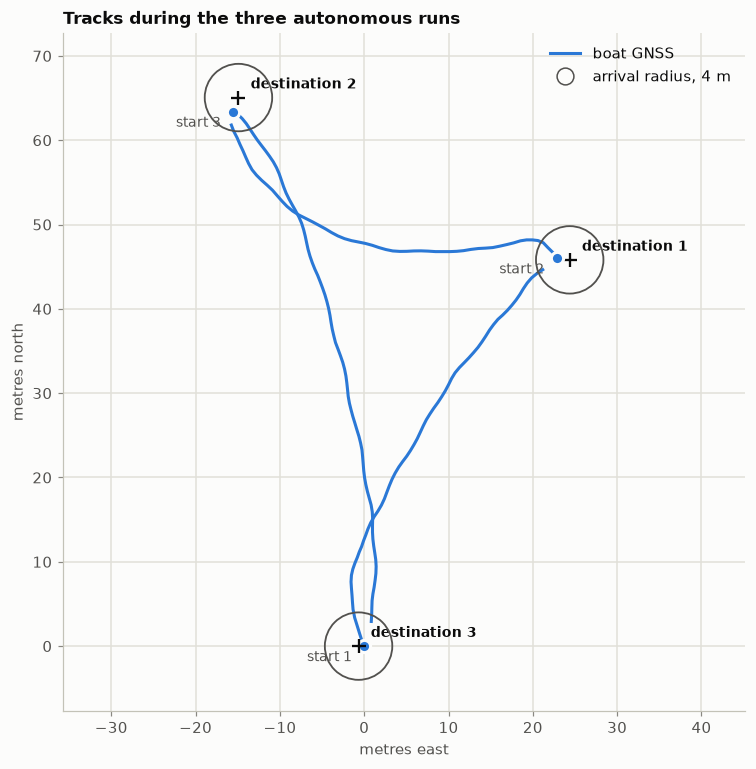

In [5]:
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

SHOW_COORDINATES = False
ARRIVAL_RADIUS_M = 4  # the boat's gnc.py

BOAT = "#2a78d6"  # categorical slot 1, as in mission 4
INK, INK_2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "font.size": 10,
    "text.color": INK, "axes.labelcolor": INK_2, "axes.edgecolor": AXIS,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 1, "axes.axisbelow": True,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False, "figure.dpi": 110,
})

origin = run_tel[runs.index[0]].query("`gps.fix_valid`").iloc[0]


def xy(lat, lon):
    """Plot coordinates: degrees, or metres east / north of the origin (equirectangular)."""
    lat, lon = np.asarray(lat, dtype=float), np.asarray(lon, dtype=float)
    if SHOW_COORDINATES:
        return lon, lat
    east = np.radians(lon - origin.lon) * np.cos(np.radians(origin.lat)) * EARTH_RADIUS_M
    north = np.radians(lat - origin.lat) * EARTH_RADIUS_M
    return east, north


fig, ax = plt.subplots(figsize=(8, 8))
for n, run in runs.iterrows():
    boat = run_tel[n].query("`gps.fix_valid`")
    ax.plot(*xy(boat.lat, boat.lon), color=BOAT, lw=2, label="boat GNSS" if n == runs.index[0] else None)
    sx, sy = xy([boat.lat.iloc[0]], [boat.lon.iloc[0]])
    ax.plot(sx, sy, "o", color=BOAT, ms=8, mec=SURFACE, mew=2, zorder=5)
    ax.annotate("start %d" % n, (sx[0], sy[0]), xytext=(-8, -3), textcoords="offset points", ha="right", va="top", color=INK_2, fontsize=9)

    dx, dy = xy([run._lat_e7 / 1e7], [run._lon_e7 / 1e7])
    if SHOW_COORDINATES:  # the radius in degrees, roughly
        rx = ARRIVAL_RADIUS_M / (EARTH_RADIUS_M * math.cos(math.radians(run._lat_e7 / 1e7))) * 180 / math.pi
    else:
        rx = ARRIVAL_RADIUS_M
    ax.add_patch(Circle((dx[0], dy[0]), rx, fill=False, color=INK_2, lw=1.2, zorder=4))
    ax.plot(dx, dy, "+", color=INK, ms=9, mew=1.5, zorder=5)
    ax.annotate("destination %d" % n, (dx[0], dy[0]), xytext=(8, 6), textcoords="offset points", color=INK, fontsize=9, fontweight="bold")

ax.set_aspect("equal", adjustable="datalim")
ax.set_xlabel("longitude (°)" if SHOW_COORDINATES else "metres east")
ax.set_ylabel("latitude (°)" if SHOW_COORDINATES else "metres north")
ax.set_title("Tracks during the three autonomous runs")
handles, labels = ax.get_legend_handles_labels()
handles.append(plt.Line2D([], [], color=INK_2, lw=1.2, marker="o", ms=11, mfc="none", ls="none"))
labels.append("arrival radius, %d m" % ARRIVAL_RADIUS_M)
ax.legend(handles, labels, loc="best")
fig.savefig(MEDIA_DIR / "tracks.png", dpi=110, bbox_inches="tight")
plt.show()

## Heading sources against the course over ground

The boat moves bow first, so the direction it travels (its course over ground, from GPS
positions) should be the direction it points. Three headings are compared with it:

| Source | Telemetry | What it is |
|---|---|---|
| magnetic compass | `compass.heading` | the BNO08x's magnetometer-based heading |
| virtual compass | `compass.virtual.heading` | what the autopilot steers by: the gyro (game rotation vector), pulled slowly towards the magnetic heading and, when the boat runs straight, towards the GPS course (virtual_compass.py) |
| target course | `nav.target_course_deg` | the bearing to the destination the autopilot is steering for |

The course is worked out from positions as in mission 4: the direction from where the boat was
2 seconds before to where it was 2 seconds after (the GNSS module's own course froze at this
speed in mission 4). The same caveats apply: only samples where the boat makes headway and is not
turning fast count; leeway (wind, current) would show up as a heading error too; and the
magnetic declination is 0 here as on the boat (`gnc.MAGNETIC_DECLINATION_DEG`), so it is part of
any error.

In [6]:
MAGNETIC_DECLINATION_DEG = 0.0  # as on the boat (gnc.py); east positive
BASELINE_S = 4  # course from the positions this many seconds apart, centred on the sample
MIN_SPEED_M_S = 0.5  # slower than this, the course isn't trusted
MAX_TURN_DEG_S = 5  # turning faster than this, heading and course legitimately differ


def wrap180(a):
    return (np.asarray(a, dtype=float) + 180) % 360 - 180


def unwrap_deg(a):
    return np.degrees(np.unwrap(np.radians(np.asarray(a, dtype=float))))


def course_from_positions(unix, lat, lon, at):
    """Course (degrees true) and speed (m/s) at times `at`, from positions BASELINE_S apart."""
    unix, lat, lon = (np.asarray(v, dtype=float) for v in (unix, lat, lon))
    la0, lo0 = np.interp(at - BASELINE_S / 2, unix, lat), np.interp(at - BASELINE_S / 2, unix, lon)
    la1, lo1 = np.interp(at + BASELINE_S / 2, unix, lat), np.interp(at + BASELINE_S / 2, unix, lon)
    east = np.radians(lo1 - lo0) * np.cos(np.radians(la0)) * EARTH_RADIUS_M
    north = np.radians(la1 - la0) * EARTH_RADIUS_M
    return np.degrees(np.arctan2(east, north)) % 360, np.hypot(east, north) / BASELINE_S


samples = []
for n in runs.index:
    boat = run_tel[n].query("`gps.fix_valid`")
    t = boat.unix.to_numpy()
    inner = (t >= t[0] + BASELINE_S / 2) & (t <= t[-1] - BASELINE_S / 2)
    course, speed = course_from_positions(t, boat.lat, boat.lon, t[inner])
    b = boat[inner]
    samples.append(pd.DataFrame({
        "run": n, "unix": t[inner], "s": t[inner] - t[0], "course": course, "speed": speed,
        "magnetic": b["compass.heading"].to_numpy() + MAGNETIC_DECLINATION_DEG,
        "virtual": b["compass.virtual.heading"].to_numpy() + MAGNETIC_DECLINATION_DEG,
        "target": b["nav.target_course_deg"].to_numpy(),
        "gyro_yaw": b["compass.gyro_yaw"].to_numpy(), "offset": b["compass.virtual.offset"].to_numpy(),
        "rudder": b["output.rudder"].to_numpy()}))
cmp = pd.concat(samples, ignore_index=True)
cmp["turn_deg_s"] = cmp.groupby("run").course.transform(lambda c: pd.Series(wrap180(np.diff(c, prepend=c.iloc[0])), index=c.index).abs())
cmp["usable"] = (cmp.speed >= MIN_SPEED_M_S) & (cmp.turn_deg_s <= MAX_TURN_DEG_S)
for src in ("magnetic", "virtual", "target"):
    cmp[src + "_error"] = wrap180(cmp[src] - cmp.course)
cmp["virtual_vs_target"] = wrap180(cmp.virtual - cmp.target)

u = cmp[cmp.usable]
print("usable samples: %d of %d (moving at %.1f m/s or more, turning %d°/s or less)" % (len(u), len(cmp), MIN_SPEED_M_S, MAX_TURN_DEG_S))
rows = {}
for n in list(runs.index) + ["all"]:
    r = u if n == "all" else u[u.run == n]
    row = {"samples": len(r)}
    for col, label in (("magnetic_error", "magnetic − course"), ("virtual_error", "virtual − course"),
                       ("target_error", "target − course"), ("virtual_vs_target", "virtual − target")):
        row[label + ", median (°)"] = round(float(r[col].median()), 1)
        row[label + ", within 10°"] = "%.0f %%" % (100 * (r[col].abs() <= 10).mean())
    rows[n] = row
pd.DataFrame(rows).T.rename_axis("run")

usable samples: 178 of 194 (moving at 0.5 m/s or more, turning 5°/s or less)


,samples,"magnetic − course, median (°)","magnetic − course, within 10°","virtual − course, median (°)","virtual − course, within 10°","target − course, median (°)","target − course, within 10°","virtual − target, median (°)","virtual − target, within 10°"
run,,,,,,,,,
1,59,12.9,36 %,16.9,12 %,13.2,29 %,3.3,90 %
2,43,32.8,0 %,37.8,2 %,33.4,0 %,3.1,81 %
3,76,16.3,3 %,17.0,1 %,12.6,32 %,4.0,83 %
all,178,16.7,13 %,18.6,5 %,15.0,23 %,3.6,85 %


**Headings and course over time.** The black line is where the boat actually went. The
autopilot steers the virtual compass (blue) onto the target course (dashed); where the two sit
together but away from the black line, the boat is steered as intended by a heading that is
wrong, and its real course is off by that much. The shaded stretches are turns or slow moments,
left out of the numbers. The chart is also saved as `../media/headings.png`.

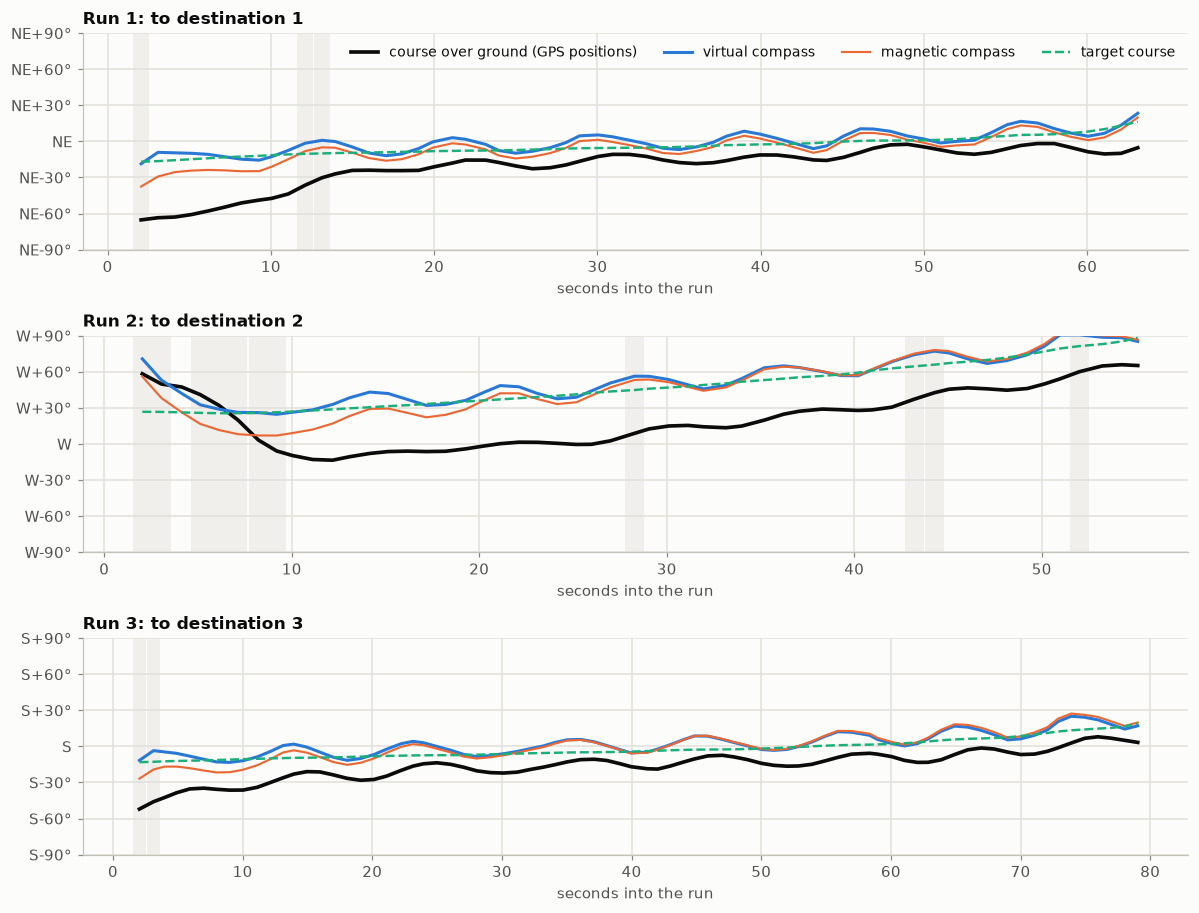

In [7]:
SERIES = {  # column: (label, colour, line width, style)
    "course": ("course over ground (GPS positions)", INK, 2.4, "-"),
    "virtual": ("virtual compass", "#2a78d6", 2, "-"),
    "magnetic": ("magnetic compass", "#eb6834", 1.4, "-"),
    "target": ("target course", "#1baf7a", 1.6, "--"),
}
CARDINAL = {0: "N", 90: "E", 180: "S", 270: "W"}

fig, axes = plt.subplots(len(runs), 1, figsize=(11, 2.8 * len(runs)))
for ax, n in zip(np.atleast_1d(axes), runs.index):
    r = cmp[cmp.run == n]
    # Centre each panel on the run's general direction, as in mission 4, so a run heading north
    # doesn't jump between the top and the bottom of the chart at 0 / 360; ±90° around it.
    mean = np.degrees(np.arctan2(np.sin(np.radians(r.course)).mean(), np.cos(np.radians(r.course)).mean()))
    centre = (round(mean / 45) * 45) % 360
    for s_, ok in zip(r.s, r.usable):
        if not ok:
            ax.axvspan(s_ - 0.5, s_ + 0.5, color="#f0efec", lw=0, zorder=0)
    for col, (label, color, lw, ls) in SERIES.items():
        y = centre + wrap180(r[col] - centre)
        y[np.abs(np.diff(y, prepend=y[0])) > 180] = np.nan  # break the line where it wraps past the edge
        ax.plot(r.s, y, color=color, lw=lw, ls=ls, label=label)
    ticks = np.arange(centre - 90, centre + 91, 30)
    ax.set_yticks(ticks, ["%s%+d°" % (["N", "NE", "E", "SE", "S", "SW", "W", "NW"][int(centre % 360) // 45], t - centre) if t != centre
                          else ["N", "NE", "E", "SE", "S", "SW", "W", "NW"][int(centre % 360) // 45] for t in ticks])
    ax.set_ylim(centre - 90, centre + 90)
    ax.set_title("Run %d: to destination %d" % (n, n))
    ax.set_xlabel("seconds into the run")
np.atleast_1d(axes)[0].legend(loc="upper right", ncol=4, fontsize=9)
fig.tight_layout()
fig.savefig(MEDIA_DIR / "headings.png", dpi=110, bbox_inches="tight")
plt.show()

## Why the virtual compass is off: the gyro's extra turning

The virtual compass follows the gyro (the BNO08x's game rotation vector) and only corrects it
slowly, so its error can only grow if the gyro registers turns the boat did not make. In the
steady part of each run (from 15 s in, after the initial turn towards the new destination) the
gyro, the magnetic compass and the course over ground should all turn at the same rate; the
difference between the gyro's rate and the course's is the gyro's error.

With the GPS correction pulling 5 % of the error per second (`GPS_GAIN_PER_S`), a gyro running
ahead by *d* °/s leaves the virtual compass behind by about *d* / 0.05, i.e. 20° for every 1°/s.
The GPS corrections themselves worked as designed: about one a second, and the virtual
compass's offset moved by exactly what they called for (the magnetic correction, ten times
weaker, contributed almost nothing).

In [8]:
GPS_GAIN_PER_S = 0.05  # virtual_compass.py
MAG_GAIN_PER_S = 0.005
STEADY_FROM_S = 15

rows = {}
for n in runs.index:
    r = cmp[(cmp.run == n) & (cmp.s >= STEADY_FROM_S)]
    dt = r.unix.iloc[-1] - r.unix.iloc[0]
    rate = {col: (unwrap_deg(r[col])[-1] - unwrap_deg(r[col])[0]) / dt for col in ("course", "gyro_yaw", "magnetic", "virtual")}
    drift = rate["gyro_yaw"] - rate["course"]
    rows[n] = {"seconds": round(dt), "course (°/s)": rate["course"], "gyro (°/s)": rate["gyro_yaw"], "magnetic (°/s)": rate["magnetic"],
               "gyro − course (°/s)": drift, "expected lag (°)": drift / GPS_GAIN_PER_S,
               "virtual − course at %d s (°)" % STEADY_FROM_S: r.virtual_error.iloc[0],
               "virtual − course at the end (°)": r.virtual_error.iloc[-1]}
display(pd.DataFrame(rows).T.rename_axis("run").round(2))

# The corrections, from the virtual compass's own telemetry: how often the GPS one ran, and
# whether the offset moved by what the two corrections called for.
V = "compass.virtual."
rows = {}
for n in runs.index:
    r = run_tel[n]
    dt = r.unix.diff().to_numpy()[1:]
    corrections = r[V + "gps_corrections"].iloc[-1] - r[V + "gps_corrections"].iloc[0]
    rows[n] = {"GPS corrections per s": corrections / (r.unix.iloc[-1] - r.unix.iloc[0]),
               "GPS error, median (°)": r[V + "last_gps_error"].median(),
               "offset change, measured (°/s)": float(np.median(wrap180(np.diff(r[V + "offset"].to_numpy())) / dt)),
               "GPS pull (°/s)": GPS_GAIN_PER_S * r[V + "last_gps_error"].median(),
               "magnetic pull (°/s)": MAG_GAIN_PER_S * r[V + "last_mag_error"].median()}
pd.DataFrame(rows).T.rename_axis("run").round(2)

,seconds,course (°/s),gyro (°/s),magnetic (°/s),gyro − course (°/s),expected lag (°),virtual − course at 15 s (°),virtual − course at the end (°)
run,,,,,,,,
1,47.0,0.40,1.41,0.72,1.02,20.32,14.34,28.68
2,40.0,1.79,2.78,1.43,0.99,19.89,48.28,20.03
3,63.0,0.39,1.10,0.46,0.71,14.25,16.43,13.77


,GPS corrections per s,"GPS error, median (°)","offset change, measured (°/s)",GPS pull (°/s),magnetic pull (°/s)
run,,,,,
1,0.95,-14.8,-0.78,-0.74,-0.02
2,0.90,-31.7,-1.63,-1.58,-0.01
3,0.96,-15.5,-0.77,-0.78,-0.00


## When the gyro ran ahead, over the whole day

Gyro yaw against the magnetic heading over the whole day (`../data/mqtt_20261025.jsonl`), in
2-minute windows, next to what the boat was doing. The log starts with the boat already at the
lake; the 7–33 kn stretch at the end is the drive back.

In [9]:
day = pd.json_normalize([dict(unix=m["unix"], **m["data"]) for m in map(json.loads, open(DATA_DIR / "mqtt_20261025.jsonl"))
                         if m["topic"].endswith("/telemetry")])
day = day[day["compass.gyro_yaw"].notna() & day["compass.heading"].notna()].reset_index(drop=True)
day["time"] = utc(day.unix)
day["gyro_u"], day["magnetic_u"] = unwrap_deg(day["compass.gyro_yaw"]), unwrap_deg(day["compass.heading"])
day["autonomous"] = day["bcu.esp32_mode"].astype("boolean").ffill().fillna(False).astype(bool)


def windows(frame, seconds, start=None, end=None):
    """Gyro against magnetic, per window of `seconds`, with what the boat was doing."""
    rows = []
    start = frame.unix.iloc[0] if start is None else start
    end = frame.unix.iloc[-1] if end is None else end
    for a in np.arange(start, end, seconds):
        w = frame[(frame.unix >= a) & (frame.unix < a + seconds)]
        if len(w) < max(4, seconds // 6):
            continue
        dt = w.unix.iloc[-1] - w.unix.iloc[0]
        gyro, magnetic = w.gyro_u.iloc[-1] - w.gyro_u.iloc[0], w.magnetic_u.iloc[-1] - w.magnetic_u.iloc[0]
        rows.append({"from (UTC)": hms(utc(a)), "gyro − magnetic (°/s)": round((gyro - magnetic) / dt, 2),
                     "gyro turned (°)": round(gyro), "magnetic turned (°)": round(magnetic),
                     "speed (kn)": round(float(w["gps.sog_kn"].median()), 1),
                     "autonomous": "%.0f %%" % (100 * w.autonomous.mean()),
                     "throttle (µs)": "%.0f–%.0f" % (w["bcu.out_throttle_us"].min(), w["bcu.out_throttle_us"].max()),
                     "rudder (µs)": "%.0f–%.0f" % (w["bcu.out_rudder_us"].min(), w["bcu.out_rudder_us"].max())})
    return pd.DataFrame(rows).set_index("from (UTC)")


windows(day, 120)

,gyro − magnetic (°/s),gyro turned (°),magnetic turned (°),speed (kn),autonomous,throttle (µs),rudder (µs)
from (UTC),,,,,,,
15:58:06,0.43,-90,-141,0.0,3 %,0–1500,0–1998
16:00:06,-0.01,0,1,0.0,0 %,1499–1500,1585–1586
16:02:06,0.13,-3,-19,0.0,0 %,1499–1500,1585–1586
16:04:06,0.04,-83,-87,0.0,0 %,1499–1500,1585–1586
16:06:06,0.05,1,-4,0.0,0 %,1499–1500,1585–1586
16:08:06,0.02,-1,-4,0.0,0 %,1499–1500,1585–1586
16:10:06,0.01,0,-1,0.0,0 %,1499–1500,1585–1586
16:12:06,0.01,1,0,0.0,0 %,1499–1500,1585–1586
16:14:06,-0.10,-137,-125,0.0,0 %,1499–1500,1585–1586


Two-minute averages hide what happens around the start of the autonomous runs. In 10-second
windows: the gyro was already off under RC (negative), crossed zero at about 16:27:50 while still
under RC, and ran at +1.4°/s while the boat sat stopped with the autonomous switch on, throttle
neutral and the rudder still. So the error does not switch on with the autopilot, the motor or
the rudder: it wanders, between about −1 and +1.5°/s over minutes.

In [10]:
switch_on = day.loc[day.autonomous & ~day.autonomous.shift(fill_value=False), "unix"]
print("autonomous switch turned on at:", [hms(utc(u)) for u in switch_on])
windows(day, 10, start=1792945560, end=1792945760)

autonomous switch turned on at: ['15:58:39', '16:28:26']


,gyro − magnetic (°/s),gyro turned (°),magnetic turned (°),speed (kn),autonomous,throttle (µs),rudder (µs)
from (UTC),,,,,,,
16:26:00,0.24,220,218,1.4,0 %,1679–1682,1689–1710
16:26:10,-0.01,232,233,1.4,0 %,1682–1684,1676–1689
16:26:20,-0.57,202,207,1.4,0 %,1683–1686,1555–1676
16:26:30,-0.35,-5,-2,1.6,0 %,1686–1700,1585–1586
16:26:40,-0.33,-2,1,1.6,0 %,1685–1701,1473–1586
16:26:50,-0.67,-175,-169,1.5,0 %,1500–1683,1332–1585
16:27:00,-0.42,-7,-4,1.5,0 %,1679–1681,1436–1586
16:27:10,-0.38,-13,-10,1.5,0 %,1681–1682,1504–1641
16:27:20,-0.43,-17,-13,1.4,0 %,1681–1683,1371–1670


## Checking the conclusion

The analysis rests on one claim: on the water, the gyro yaw (the BNO08x's game rotation vector)
registered turns the boat did not make. These checks try to break it:

1. **Is the telemetry consistent?** The virtual heading should be the gyro yaw plus the offset in
   every message.
2. **Wrap-arounds or glitches?** At one message a second, a jump past 359° → 0° or a bad reading
   would inflate the totals.
3. **Total turning under way on the autopilot.** Two independent references, the GPS course from
   positions and the magnetic heading, against the gyro. Also per 20-second block, so one bad
   moment can't make the whole difference.
4. **Drift or scale error?** A gyro that reads turns too large (scale) would grow with turning; a
   drift is a constant added rate. Fitted second by second against the magnetic heading (the GPS
   course is itself a 4-second average, which flattens a fit against it).
5. **Without motion.** The stretch where the boat sat stopped on the water with the autonomous
   switch on, throttle neutral and the rudder still.

In [11]:
checks = []
V = "compass.virtual."

ident = wrap180(day[V + "heading"] - (day["compass.gyro_yaw"] + day[V + "offset"]))
checks.append(("1. virtual heading = gyro yaw + offset", "within %.2f° in all %d messages" % (np.nanmax(np.abs(ident)), np.isfinite(ident).sum())))

navigating = (day["nav.state"] == "navigating").to_numpy()
jumps = {col: np.abs(wrap180(np.diff(day[col].to_numpy())))[navigating[1:]] for col in ("compass.gyro_yaw", "compass.heading")}
big = np.where(jumps["compass.gyro_yaw"] > 90)[0]
checks.append(("2. largest change between messages while navigating",
               "gyro %.0f°, magnetic %.0f°; changes over 90°: %d (gyro), %d (magnetic), at the same moments" % (
                   jumps["compass.gyro_yaw"].max(), jumps["compass.heading"].max(), len(big), (jumps["compass.heading"] > 90).sum())))

fix = day["gps.fix_valid"].astype(bool).to_numpy()
day["course"], day["speed"] = course_from_positions(day.unix[fix], day["gps.lat_e7"][fix] / 1e7, day["gps.lon_e7"][fix] / 1e7,
                                                    day.unix.to_numpy())
step = pd.DataFrame({"seconds": day.unix.diff(), "gyro": wrap180(day["compass.gyro_yaw"].diff()), "magnetic": wrap180(day["compass.heading"].diff()),
                     "course": wrap180(day.course.diff()), "speed": day.speed,
                     "under_way": navigating & day.autonomous.to_numpy() & (day.speed.to_numpy() > MIN_SPEED_M_S)})
u_way = step[step.under_way].dropna()
total = u_way[["seconds", "gyro", "magnetic", "course"]].sum()
checks.append(("3. turned in total, under way on the autopilot (%.0f s)" % total.seconds,
               "GPS course %+.0f°, magnetic %+.0f°, gyro %+.0f°" % (total.course, total.magnetic, total.gyro)))
checks.append(("   as rates", "gyro − course %+.2f°/s, magnetic − course %+.2f°/s, gyro − magnetic %+.2f°/s" % (
    (total.gyro - total.course) / total.seconds, (total.magnetic - total.course) / total.seconds, (total.gyro - total.magnetic) / total.seconds)))
blocks = u_way.assign(block=np.arange(len(u_way)) // 20).groupby("block").sum()
blocks = blocks[blocks.seconds > 15]
ahead = (blocks.gyro - blocks.course) / blocks.seconds
checks.append(("   per 20-s block, gyro − course", "ahead in %d of %d blocks: %s °/s" % ((ahead > 0).sum(), len(ahead), np.round(ahead.to_numpy(), 1).tolist())))
checks.append(("   per 20-s block, magnetic − course", "%s °/s" % np.round(((blocks.magnetic - blocks.course) / blocks.seconds).to_numpy(), 1).tolist()))

rates = (u_way[["gyro", "magnetic"]].div(u_way.seconds, axis=0)).rolling(3, center=True).mean().dropna()
scale, drift = np.polyfit(rates.magnetic, rates.gyro, 1)
checks.append(("4. gyro rate against magnetic rate, second by second", "gyro = %+.2f°/s + %.2f × magnetic  (scale 1 = no scale error)" % (drift, scale)))

stopped = day[(day.unix >= 1792945706) & (day.unix < 1792945750)]
turned = lambda col: wrap180(stopped[col].diff().dropna()).sum()
dt = stopped.unix.iloc[-1] - stopped.unix.iloc[0]
checks.append(("5. stopped on the water, %s–%s (%.0f s)" % (hms(stopped.time.iloc[0]), hms(stopped.time.iloc[-1]), dt),
               "throttle %.0f µs, speed %.1f m/s: magnetic %+.0f°, gyro %+.0f° (gyro − magnetic %+.1f°/s)" % (
                   stopped["bcu.out_throttle_us"].median(), stopped.speed.median(), turned("compass.heading"), turned("compass.gyro_yaw"),
                   (turned("compass.gyro_yaw") - turned("compass.heading")) / dt)))
pd.set_option("display.max_colwidth", None)
pd.DataFrame(checks, columns=["check", "result"]).set_index("check")

,result
check,
1. virtual heading = gyro yaw + offset,within 0.10° in all 3256 messages
2. largest change between messages while navigating,"gyro 94°, magnetic 92°; changes over 90°: 1 (gyro), 1 (magnetic), at the same moments"
"3. turned in total, under way on the autopilot (321 s)","GPS course +348°, magnetic +368°, gyro +620°"
as rates,"gyro − course +0.84°/s, magnetic − course +0.06°/s, gyro − magnetic +0.78°/s"
"per 20-s block, gyro − course","ahead in 15 of 16 blocks: [0.7, 1.0, 0.3, 0.1, 0.6, 0.4, 3.8, 1.5, 1.2, 0.2, 0.6, 0.8, 1.2, -0.4, 0.5, 1.1] °/s"
"per 20-s block, magnetic − course","[-0.2, 0.3, -0.4, -0.8, -0.1, -0.2, 2.8, 0.1, -0.0, -0.4, -0.0, 0.2, 0.5, -1.1, -0.1, 0.6] °/s"
"4. gyro rate against magnetic rate, second by second",gyro = +0.77°/s + 1.01 × magnetic (scale 1 = no scale error)
"5. stopped on the water, 16:28:26–16:29:09 (43 s)","throttle 1500 µs, speed 0.0 m/s: magnetic +64°, gyro +119° (gyro − magnetic +1.3°/s)"


What the checks show:

- **The data is consistent and free of glitches**: the virtual compass's own numbers add up, and
  the one change over 90° between messages is a real fast turn, seen by the gyro and the magnetic
  heading at the same moment.
- **Two independent references agree with each other and not with the gyro.** Under way on the
  autopilot, the GPS course and the magnetic heading turned about the same amount; the gyro turned
  about 270° more, ahead of the course in nearly every 20-second block.
- **It is a drift, not a misreading of turns**: against the magnetic heading the gyro's scale is
  1.0, with a constant +0.8°/s on top.
- **It is there without motion**: stopped on the water, the gyro ran 1.3°/s ahead of the
  magnetic heading while the boat drifted round.
- **It explains the virtual compass's lag in numbers**: the GPS correction removed exactly what it
  is designed to (5 % of the error a second), and a 0.8°/s drift against that pull settles at
  0.8 / 0.05 = 16° of lag, what runs 1 and 3 show.

What the data does *not* prove is the cause; see the bench tests and the change below.

## Bench tests after the mission

Run the same day on the main controller over USB, the boat on the bench, heeled to the left more
than on the water; the Body Control Unit in autopilot mode. Each test logged the gyro yaw and the
magnetic heading 5–20 times a second (the logs are not in this repository).

| Test | Gyro − magnetic |
|---|---|
| Still, 40 s, three times | +0.01 to +0.06°/s |
| Rudder swept slowly, 1240–1930 µs, 40 s | +0.04°/s |
| Rudder jumping between the ends every second (as the autopilot did), 40 s | +0.02°/s |
| Motor at 20 % (propeller in the air), 30 s | −0.04°/s |
| Motor at 20 % with the rudder jumping, 30 s | 0.00°/s |
| Turned back and forth by hand, ±25° at up to 114°/s, 50 s | −0.04°/s |
| Bounced and rocked by hand without turning, 50 s | −0.14°/s (uncertain: shaking also disturbs the magnetic heading) |
| **On the water, on the autopilot** | **+0.8°/s** |

Nothing on the bench reproduces it: not the rudder servo, the motor, the heel, rotating or shaking.
On the bench, and whenever the boat was truly still, the gyro is right; on the water and while
being carried it wandered by about 1°/s for minutes at a time.

## Findings: the curve on the way to destination 2

- **The autopilot did its job.** In every run it kept the virtual compass within a few degrees
  of the target course (median +3 to +4°).
- **The virtual compass was wrong, always in the same direction.** It read clockwise of the
  boat's real direction of travel, by a median of about 17° in runs 1 and 3 and 38° in run 2.
  Steering a heading that reads too far right puts the boat's real course to the *left* of the
  target. The bearing to the destination then keeps swinging as the boat drifts off the line,
  and the track curves: most in run 2, where the error was largest (it also started about 48° out
  after the turn towards destination 2).
- **The cause is the gyro yaw drifting by about +0.8°/s on the water**, confirmed against both the
  GPS course and the magnetic heading (see *Checking the conclusion*). The virtual compass and its
  corrections worked as designed: a correction proportional to the error can only hold a steady
  drift at a lag of drift / 0.05, i.e. 16° here.
- **The drift wandered** between about −1 and +1.5°/s over minutes, independent of the autopilot,
  the motor and the rudder, and fell to 0 whenever the boat was truly still. On the bench the gyro
  is right in every test. That points to the chip's own estimate of its gyro bias: with dynamic
  calibration on, the BNO08x keeps re-learning it, which works when it is still and apparently
  goes wrong when it never quite is (floating, being carried). Not proven yet.
- **The magnetic compass followed the boat's turns this time**, unlike mission 4 (its turning
  rate matched the track), but it also read 13–33° clockwise of the course. Wind or current
  pushing the boat sideways is unlikely to explain it: the error has the same sign heading
  north-east, west and south. A magnetic deviation that depends on the direction (as in mission 4)
  fits better. It barely affects steering: the virtual compass only starts from it and then pulls
  towards it at 0.5 %/s.
- **The rudder trim was about 5 % too far right.** The boat went straight with the autopilot
  holding about −4 % of rudder, i.e. at about +12 % (as mission 4 also found), not the +17 % the
  transmitter's trim gave. Holding that rudder costs the proportional autopilot a steady 3–4°
  course error.

## Changes after this mission

| Change | Where | Why |
|---|---|---|
| **Gyro dynamic calibration turned off** on the BNO08x (accelerometer and magnetometer calibration unchanged, still on) | `electronics/main_controller_esp32_mp/compass.py` | Stop the chip re-learning its gyro bias on the move. It keeps the saved gyro calibration, which was right on the bench (gyro − magnetic about 0.003°/s after the change) |
| Rudder centre 1587 → 1560 µs (+17 → +12 %) | `config.py` on the board | Where the boat actually goes straight |

**What the next water session should show:** the gyro turning as much as the GPS course and the
magnetic heading (check 3 above, rerun on the new data). A small *constant* drift is acceptable:
at 0.2°/s the virtual compass's lag would be about 4°. If the gyro still wanders, the next
candidates are the chip's other rotation-vector reports (gyro-integrated, AR/VR-stabilised) or
learning the drift in the virtual compass.